# Pendahuluan

Data preprocessing dan EDA.

## Introduction to Capstone Project

Mengetahui tingkat kemiskinan sebuah rumah tangga adalah langkah awal agar bantuan sosial tepat sasaran. Di banyak negara berkembang, termasuk Kosta Rika, pendapatan rumah tangga sulit diverifikasi karena banyak yang bekerja di sektor informal. Karena itu digunakan pendekatan *Proxy Means Test* (PMT): tingkat kemiskinan diprediksi dari karakteristik yang mudah diamati, seperti kondisi bangunan rumah, aset yang dimiliki, tingkat pendidikan, dan komposisi anggota rumah tangga. Tujuan bisnis yang ingin dicapai yaitu membentuk model prediksi tingkat kemiskinan rumah tangga berdasarkan feature-feature yang ada untuk membantu pemerintah atau lembaga sosial menentukan penerima bantuan secara tepat dan akurat.

**Problem Statement**

Masalah yang ingin kita selesaikan adalah memprediksi tingkat kemiskinan rumah tangga (`Target`) secara tepat dan akurat. Perlu dilakukan analisis faktor-faktor yang paling berkaitan dengan tingkat kemiskinan.

**About Datasets**

Dataset yang digunakan adalah **Costa Rican Household Poverty Level** dari kompetisi *Costa Rican Household Poverty Level Prediction* (Inter-American Development Bank). Setiap baris adalah **satu individu** anggota rumah tangga, dan seluruh anggota dalam satu rumah tangga (`idhogar`) memiliki nilai `Target` yang sama. Dataset ini terdiri dari 9.557 baris data dan 143 kolom (141 feature, 1 `Target`, dan kolom identitas `Id` serta `idhogar`).

Kolom `Target` adalah bilangan bulat 1-4:

1. `1` = kemiskinan ekstrem (*extreme poverty*)
2. `2` = kemiskinan moderat (*moderate poverty*)
3. `3` = rumah tangga rentan (*vulnerable households*)
4. `4` = rumah tangga tidak rentan (*non vulnerable households*)

Kolom-kolom penting yang akan banyak dipakai:

- `v2a1`: pembayaran sewa bulanan.
- `rooms`: jumlah kamar di rumah; `overcrowding`: rata-rata orang per kamar.
- `v18q`: apakah memiliki tablet; `refrig`, `computer`, `television`: kepemilikan kulkas, komputer, TV.
- `hhsize`: jumlah anggota rumah tangga; `hogar_nin`: jumlah anak 0-19 tahun; `hogar_adul`: jumlah dewasa.
- `escolari`: lama sekolah (tahun) individu; `meaneduc`: rata-rata lama sekolah anggota dewasa (18+); `edjefe` dan `edjefa`: lama sekolah kepala rumah tangga laki-laki / perempuan.
- `dependency`: rasio ketergantungan (anggota < 19 atau > 64 tahun dibanding anggota 19-64 tahun).
- `epared1/2/3`, `etecho1/2/3`, `eviv1/2/3`: kondisi dinding, atap, dan lantai (1 = buruk, 2 = sedang, 3 = baik); `pisomoscer`: lantai mosaik/keramik; `cielorazo`: rumah memiliki langit-langit.
- `area1`: wilayah perkotaan; `age`: usia; `parentesco1`: 1 jika individu adalah kepala rumah tangga.
- Kolom berawalan `SQB` adalah kuadrat dari kolom lain.

**Objective of Capstone 1**

Tujuan dari Capstone adalah melakukan data preprocessing termasuk Exploratory Data Analysis untuk menggali insight dari data rumah tangga hingga proses feature selection dan dimensionality reduction. Hasil akhir yang ingin dicapai yaitu mendapatkan insight data tingkat kemiskinan rumah tangga dan data yang siap untuk dimodelkan pada tahap selanjutnya.

**Metrics**

Tahap untuk mendukung dalam menyelesaikan problem statement yang ada dan akan digunakan untuk memantau kinerja solusi. Berikut metrics yang termasuk :
1. Jumlah rumah tangga pada masing-masing tingkat kemiskinan
2. Proporsi rumah tangga perkotaan dan pedesaan pada masing-masing tingkat kemiskinan
3. Rata-rata pendidikan dewasa (`meaneduc`) pada masing-masing tingkat kemiskinan
4. Korelasi tingkat kemiskinan terhadap tiap variabel yang ada pada dataset (pendidikan, kondisi rumah, kepadatan hunian, aset, dan variabel lainnya)

**Persiapan**

Menyiapkan libraries yang diperlukan

In [1]:
#Import libraries
import numpy as np
import pandas as pd
import math
import random
import seaborn as sns
from scipy.stats import pearsonr, jarque_bera
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import cross_val_score
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [2]:
'''Menampilkan lima baris teratas'''
# Memuat dataset Costa Rican Household Poverty Level (train.csv)
data = pd.read_csv("train.csv")

# Menampilkan lima baris teratas
data.head()

,Id,v2a1,hacdor,rooms,hacapo,v14a,refrig,v18q,v18q1,r4h1,...,SQBescolari,SQBage,SQBhogar_total,SQBedjefe,SQBhogar_nin,SQBovercrowding,SQBdependency,SQBmeaned,agesq,Target
0,ID_279628684,190000.0,0,3,0,1,1,0,NaN,0,...,100,1849,1,100,0,1.000000,0.0,100.0,1849,4
1,ID_f29eb3ddd,135000.0,0,4,0,1,1,1,1.0,0,...,144,4489,1,144,0,1.000000,64.0,144.0,4489,4
2,ID_68de51c94,NaN,0,8,0,1,1,0,NaN,0,...,121,8464,1,0,0,0.250000,64.0,121.0,8464,4
3,ID_d671db89c,180000.0,0,5,0,1,1,1,1.0,0,...,81,289,16,121,4,1.777778,1.0,121.0,289,4
4,ID_d56d6f5f5,180000.0,0,5,0,1,1,1,1.0,0,...,121,1369,16,121,4,1.777778,1.0,121.0,1369,4


In [3]:
'''Menampilkan lima baris terbawah'''
# Menampilkan lima baris terbawah
data.tail()

,Id,v2a1,hacdor,rooms,hacapo,v14a,refrig,v18q,v18q1,r4h1,...,SQBescolari,SQBage,SQBhogar_total,SQBedjefe,SQBhogar_nin,SQBovercrowding,SQBdependency,SQBmeaned,agesq,Target
9552,ID_d45ae367d,80000.0,0,6,0,1,1,0,NaN,0,...,81,2116,25,81,1,1.5625,0.0625,68.0625,2116,2
9553,ID_c94744e07,80000.0,0,6,0,1,1,0,NaN,0,...,0,4,25,81,1,1.5625,0.0625,68.0625,4,2
9554,ID_85fc658f8,80000.0,0,6,0,1,1,0,NaN,0,...,25,2500,25,81,1,1.5625,0.0625,68.0625,2500,2
9555,ID_ced540c61,80000.0,0,6,0,1,1,0,NaN,0,...,121,676,25,81,1,1.5625,0.0625,68.0625,676,2
9556,ID_a38c64491,80000.0,0,6,0,1,1,0,NaN,0,...,64,441,25,81,1,1.5625,0.0625,68.0625,441,2


In [4]:
'''Menampilkan jumlah baris dan kolom'''
# Melihat jumlah dataset (jumlah baris dan kolom)
data.shape

(9557, 143)

In [5]:
'''Menampilkan nama kolom'''
# Melihat columns apa saja yang ada dalam dataset
data.columns

Index(['Id', 'v2a1', 'hacdor', 'rooms', 'hacapo', 'v14a', 'refrig', 'v18q',
       'v18q1', 'r4h1',
       ...
       'SQBescolari', 'SQBage', 'SQBhogar_total', 'SQBedjefe', 'SQBhogar_nin',
       'SQBovercrowding', 'SQBdependency', 'SQBmeaned', 'agesq', 'Target'],
      dtype='str', length=143)

In [6]:
'''Menampilkan persebaran data untuk data numerik'''
# Melihat persebaran data
data.describe()

,v2a1,hacdor,rooms,hacapo,v14a,refrig,v18q,v18q1,r4h1,r4h2,...,SQBescolari,SQBage,SQBhogar_total,SQBedjefe,SQBhogar_nin,SQBovercrowding,SQBdependency,SQBmeaned,agesq,Target
count,2.697000e+03,9557.000000,9557.000000,9557.000000,9557.000000,9557.000000,9557.000000,2215.000000,9557.000000,9557.000000,...,9557.000000,9557.000000,9557.000000,9557.000000,9557.000000,9557.000000,9557.000000,9552.000000,9557.000000,9557.000000
mean,1.652316e+05,0.038087,4.955530,0.023648,0.994768,0.957623,0.231767,1.404063,0.385895,1.559171,...,74.222769,1643.774302,19.132887,53.500262,3.844826,3.249485,3.900409,102.588867,1643.774302,3.302292
std,1.504571e+05,0.191417,1.468381,0.151957,0.072145,0.201459,0.421983,0.763131,0.680779,1.036574,...,76.777549,1741.197050,18.751395,78.445804,6.946296,4.129547,12.511831,93.516890,1741.197050,1.009565
min,0.000000e+00,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,0.000000,0.000000,0.040000,0.000000,0.000000,0.000000,1.000000
25%,8.000000e+04,0.000000,4.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,...,16.000000,289.000000,9.000000,0.000000,0.000000,1.000000,0.111111,36.000000,289.000000,3.000000
50%,1.300000e+05,0.000000,5.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,...,36.000000,961.000000,16.000000,36.000000,1.000000,2.250000,0.444444,81.000000,961.000000,4.000000
75%,2.000000e+05,0.000000,6.000000,0.000000,1.000000,1.000000,0.000000,2.000000,1.000000,2.000000,...,121.000000,2601.000000,25.000000,81.000000,4.000000,4.000000,1.777778,134.560010,2601.000000,4.000000
max,2.353477e+06,1.000000,11.000000,1.000000,1.000000,1.000000,1.000000,6.000000,5.000000,8.000000,...,441.000000,9409.000000,169.000000,441.000000,81.000000,36.000000,64.000000,1369.000000,9409.000000,4.000000


In [7]:
'''Menampilkan jumlah data yang unik untuk semua kolom'''
# Melihat uniqueness data
data.nunique()

Id                 9557
v2a1                157
hacdor                2
rooms                11
hacapo                2
                   ... 
SQBovercrowding      38
SQBdependency        31
SQBmeaned           155
agesq                97
Target                4
Length: 143, dtype: int64

In [8]:
'''Menampilkan informasi dalam dataframe'''
# Melihat informasi dari dataset
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 9557 entries, 0 to 9556
Columns: 143 entries, Id to Target
dtypes: float64(8), int64(130), str(5)
memory usage: 10.7 MB


**Menentukan unit analisis**

Pada data ini satu baris adalah satu individu, padahal `Target` adalah label **tingkat rumah tangga** (semua anggota satu rumah tangga memiliki `Target` yang sama). Jika semua baris dipakai, anggota dari rumah tangga yang sama bisa muncul sekaligus di data train dan data test sehingga performa model terlihat terlalu bagus (*data leakage*). Karena itu, **satu baris per rumah tangga**, yaitu baris kepala rumah tangga (`parentesco1 == 1`). Kolom seperti `meaneduc`, `hhsize`, `overcrowding`, dan `hogar_nin` sudah merangkum informasi seluruh anggota rumah tangga.

In [9]:
# Cek konsistensi Target dalam satu rumah tangga dan jumlah kepala rumah tangga
print("Jumlah baris (individu)        :", data.shape[0])
print("Jumlah rumah tangga (idhogar)  :", data['idhogar'].nunique())
print("Jumlah kepala rumah tangga     :", (data['parentesco1'] == 1).sum())

# Hanya ambil kepala rumah tangga
data = data[data['parentesco1'] == 1].reset_index(drop=True)
print("Jumlah baris setelah difilter  :", data.shape[0])

Jumlah baris (individu)        : 9557
Jumlah rumah tangga (idhogar)  : 2988
Jumlah kepala rumah tangga     : 2973
Jumlah baris setelah difilter  : 2973


**Data Quality**

Melakukan pengecekan karakter, handling missing value, outlier, duplikat dan data imbalance serta skewness.

In [10]:
# Kolom identitas tidak dipakai untuk analisis, cek dulu kolom yang bukan numerik
print("Kolom non-numerik:", data.select_dtypes(exclude='number').columns.tolist())

# Buang kolom identitas
data = data.drop(columns=['Id', 'idhogar'])

# Kolom non-numerik yang tersisa
data.select_dtypes(exclude='number').head()

Kolom non-numerik: ['Id', 'idhogar', 'dependency', 'edjefe', 'edjefa']


,dependency,edjefe,edjefa
0,no,10,no
1,8,12,no
2,8,no,11
3,yes,11,no
4,yes,9,no


Terdapat tiga feature yang mengalami kesalahan tipe data (`dependency`, `edjefe`, dan `edjefa`). Seharusnya ketiganya numerik, tetapi berisi teks `yes` dan `no` yang bercampur dengan angka. Berdasarkan keterangan dataset: 
- `yes` berarti 1
- `no` berarti 0

In [11]:
'''Menampilkan jumlah data per item'''
# Melihat jumlah nilai unik dari kolom 'dependency'
data['dependency'].value_counts().head(8)

dependency
no           815
yes          653
.5           462
8            249
2            201
.33333334    146
1.5          140
.66666669     96
Name: count, dtype: int64

In [12]:
# Menemukan baris dengan kolom 'edjefe' bernilai 'yes' atau 'no'
data[data['edjefe'].isin(['yes', 'no'])][['edjefe', 'edjefa', 'dependency']].head()

,edjefe,edjefa,dependency
2,no,11,8
5,no,11,yes
6,no,4,yes
7,no,10,3
16,no,9,no


In [13]:
'''Ubah teks yes/no menjadi angka'''
# Ganti 'yes' menjadi 1 dan 'no' menjadi 0 pada tiga kolom, lalu ubah tipenya menjadi float
for col in ['dependency', 'edjefe', 'edjefa']:
    data[col] = data[col].replace({'yes': '1', 'no': '0'}).astype(float)

# Cek kembali apakah masih ada nilai 'yes'/'no'
print(data[['dependency', 'edjefe', 'edjefa']].dtypes)
data['dependency'].value_counts().head(8)

dependency    float64
edjefe        float64
edjefa        float64
dtype: object


dependency
0.000000    815
1.000000    653
0.500000    462
8.000000    249
2.000000    201
0.333333    146
1.500000    140
0.666667     96
Name: count, dtype: int64

**Pelabelan data categorical**

Untuk memudahkan EDA, beberapa kolom indikator (0/1) dipilih sebagai data kategorikal, diubah menjadi `object`, lalu diberi label. Kolom `Target` juga diberi label.

In [14]:
'''Memilih mana data yang kategorikal dan ubah menjadi object'''
# Melakukan handling kolom menjadi kategorikal
lst = ['v18q', 'refrig', 'computer', 'television', 'cielorazo', 'pisomoscer',
       'epared3', 'etecho3', 'eviv3', 'area1', 'Target']
data[lst] = data[lst].astype(object)

# Melihat perubahan
data[lst].dtypes

v18q          object
refrig        object
computer      object
television    object
cielorazo     object
pisomoscer    object
epared3       object
etecho3       object
eviv3         object
area1         object
Target        object
dtype: object

In [15]:
# Pelabelan data categorical
label_maps = {
    'v18q'      : {0: 'Tidak', 1: 'Ya'},
    'refrig'    : {0: 'Tidak', 1: 'Ya'},
    'computer'  : {0: 'Tidak', 1: 'Ya'},
    'television': {0: 'Tidak', 1: 'Ya'},
    'cielorazo' : {0: 'Tidak', 1: 'Ya'},
    'pisomoscer': {0: 'Tidak', 1: 'Ya'},
    'epared3'   : {0: 'Tidak', 1: 'Ya'},
    'etecho3'   : {0: 'Tidak', 1: 'Ya'},
    'eviv3'     : {0: 'Tidak', 1: 'Ya'},
    'area1'     : {0: 'Pedesaan', 1: 'Perkotaan'},
    'Target'    : {1: 'Ekstrem', 2: 'Moderat', 3: 'Rentan', 4: 'Tidak rentan'}
}
for col, mapping in label_maps.items():
    data[col] = data[col].replace(mapping)

target_order = ['Ekstrem', 'Moderat', 'Rentan', 'Tidak rentan']
data[lst].head()

,v18q,refrig,computer,television,cielorazo,pisomoscer,epared3,etecho3,eviv3,area1,Target
0,Tidak,Ya,Tidak,Tidak,Ya,Ya,Tidak,Tidak,Tidak,Perkotaan,Tidak rentan
1,Ya,Ya,Tidak,Tidak,Ya,Tidak,Tidak,Tidak,Tidak,Perkotaan,Tidak rentan
2,Tidak,Ya,Tidak,Tidak,Ya,Ya,Tidak,Ya,Ya,Perkotaan,Tidak rentan
3,Ya,Ya,Tidak,Tidak,Ya,Ya,Ya,Ya,Ya,Perkotaan,Tidak rentan
4,Tidak,Ya,Tidak,Tidak,Ya,Ya,Tidak,Tidak,Tidak,Perkotaan,Tidak rentan


In [16]:
'''Memisahkan data numerical dengan categorical'''
# Pisahkan numerical dan categorical
numerical_col = data.select_dtypes(include='number')
categorical_col = data.select_dtypes(exclude='number')

print("Jumlah kolom numerik   :", numerical_col.shape[1])
print("Jumlah kolom kategorikal:", categorical_col.shape[1])

Jumlah kolom numerik   : 130
Jumlah kolom kategorikal: 11


In [ ]:
# Pengecekan karakter dari data kategorikal
for i in categorical_col:
    print("Berikut ini merupakan informasi kolom: {} dengan {}".format(i, data[i].unique()))
    print()

Berikut ini merupakan informasi: refrig dengan ['Ya' 'Tidak']

Berikut ini merupakan informasi: v18q dengan ['Tidak' 'Ya']

Berikut ini merupakan informasi: pisomoscer dengan ['Ya' 'Tidak']

Berikut ini merupakan informasi: cielorazo dengan ['Ya' 'Tidak']

Berikut ini merupakan informasi: epared3 dengan ['Tidak' 'Ya']

Berikut ini merupakan informasi: etecho3 dengan ['Tidak' 'Ya']

Berikut ini merupakan informasi: eviv3 dengan ['Tidak' 'Ya']

Berikut ini merupakan informasi: computer dengan ['Tidak' 'Ya']

Berikut ini merupakan informasi: television dengan ['Tidak' 'Ya']

Berikut ini merupakan informasi: area1 dengan ['Perkotaan' 'Pedesaan']

Berikut ini merupakan informasi: Target dengan ['Tidak rentan' 'Moderat' 'Rentan' 'Ekstrem']



Selanjutnya handling missing value.

In [ ]:
'''Menampilkan missing value'''
# Check missing values
missing = data.isnull().sum()
print("Hasil missing value:\n", missing[missing > 0])

Hasil missing value:
 v2a1         2156
v18q1        2318
rez_esc      2972
meaneduc        3
SQBmeaned       3
dtype: int64


Terdapat 5 kolom dengan missing value. Tiga kolom pertama (`v2a1`, `v18q1`, `rez_esc`) bukan kesalahan input, melainkan kosong karena memang **tidak relevan**, sehingga diisi dengan 0 (bukan modus/rata-rata) agar tidak menciptakan informasi palsu:

1. `v2a1` (sewa bulanan): kosong pada rumah tangga yang tidak menyewa (milik sendiri, dipinjami, dll.).
2. `v18q1` (jumlah tablet): kosong ketika rumah tangga tidak memiliki tablet (`v18q` = Tidak).
3. `rez_esc` (tahun tertinggal sekolah): hanya relevan untuk usia 7-19 tahun, sedangkan kepala rumah tangga berusia dewasa.

Dua kolom lain (`meaneduc` dan `SQBmeaned`) hanya kosong pada sangat sedikit baris, sehingga diisi dengan nilai tengah (median).

In [19]:
# Bukti: v2a1 kosong terutama pada rumah milik sendiri (tipovivi1) atau dipinjami/lainnya (tipovivi4, tipovivi5)
print(data[data['v2a1'].isnull()][['tipovivi1', 'tipovivi2', 'tipovivi3', 'tipovivi4', 'tipovivi5']].sum())

# Bukti: v18q1 kosong hanya pada rumah tangga yang tidak punya tablet
print()
print(data[data['v18q1'].isnull()]['v18q'].value_counts())

tipovivi1    1856
tipovivi2       0
tipovivi3       0
tipovivi4      46
tipovivi5     254
dtype: int64

v18q
Tidak    2318
Name: count, dtype: int64


In [20]:
'''Mengisi missing value'''
# Fillna dengan 0 pada kolom yang kosong karena tidak relevan
for col in ['v2a1', 'v18q1', 'rez_esc']:
    data[col] = data[col].fillna(0)

# Fillna pada kolom 'meaneduc' dan 'SQBmeaned' dengan median
median_meaneduc = data['meaneduc'].median()
data['meaneduc'] = data['meaneduc'].fillna(median_meaneduc)

median_sqbmeaned = data['SQBmeaned'].median()
data['SQBmeaned'] = data['SQBmeaned'].fillna(median_sqbmeaned)

In [21]:
'''Menampilkan missing value'''
# Check missing values kembali
print("Total missing value:", data.isnull().sum().sum())

Total missing value: 0


Selanjutnya, Melakukan pengecekan baris yang duplikat.

In [22]:
'''Menampilkan data duplikat ada berapa'''
# Memeriksa duplikat data
data.duplicated().sum()

np.int64(0)

In [23]:
# Menampilkan baris data duplicate
data[data.duplicated()]

,v2a1,hacdor,rooms,hacapo,v14a,refrig,v18q,v18q1,r4h1,r4h2,...,SQBescolari,SQBage,SQBhogar_total,SQBedjefe,SQBhogar_nin,SQBovercrowding,SQBdependency,SQBmeaned,agesq,Target


Jika terdapat duplikat, perlu melakukan penghapusan duplikat data agar tidak ada data yang duplikat dalam dataset. Pada data ini tidak ditemukan duplikat setelah kolom identitas dibuang, namun kode di bawah ini dijalankan sebagai pengaman saja.

In [24]:
'''Menghapus data duplikat dan mempertahankan data pertama'''
# Menghapus data duplikat
data.drop_duplicates(keep='first', inplace=True)

# Memeriksa ulang duplikat data
data.duplicated().sum()

np.int64(0)

Selanjutnya, menampilkan outliers dan menghapus data yang outlier.

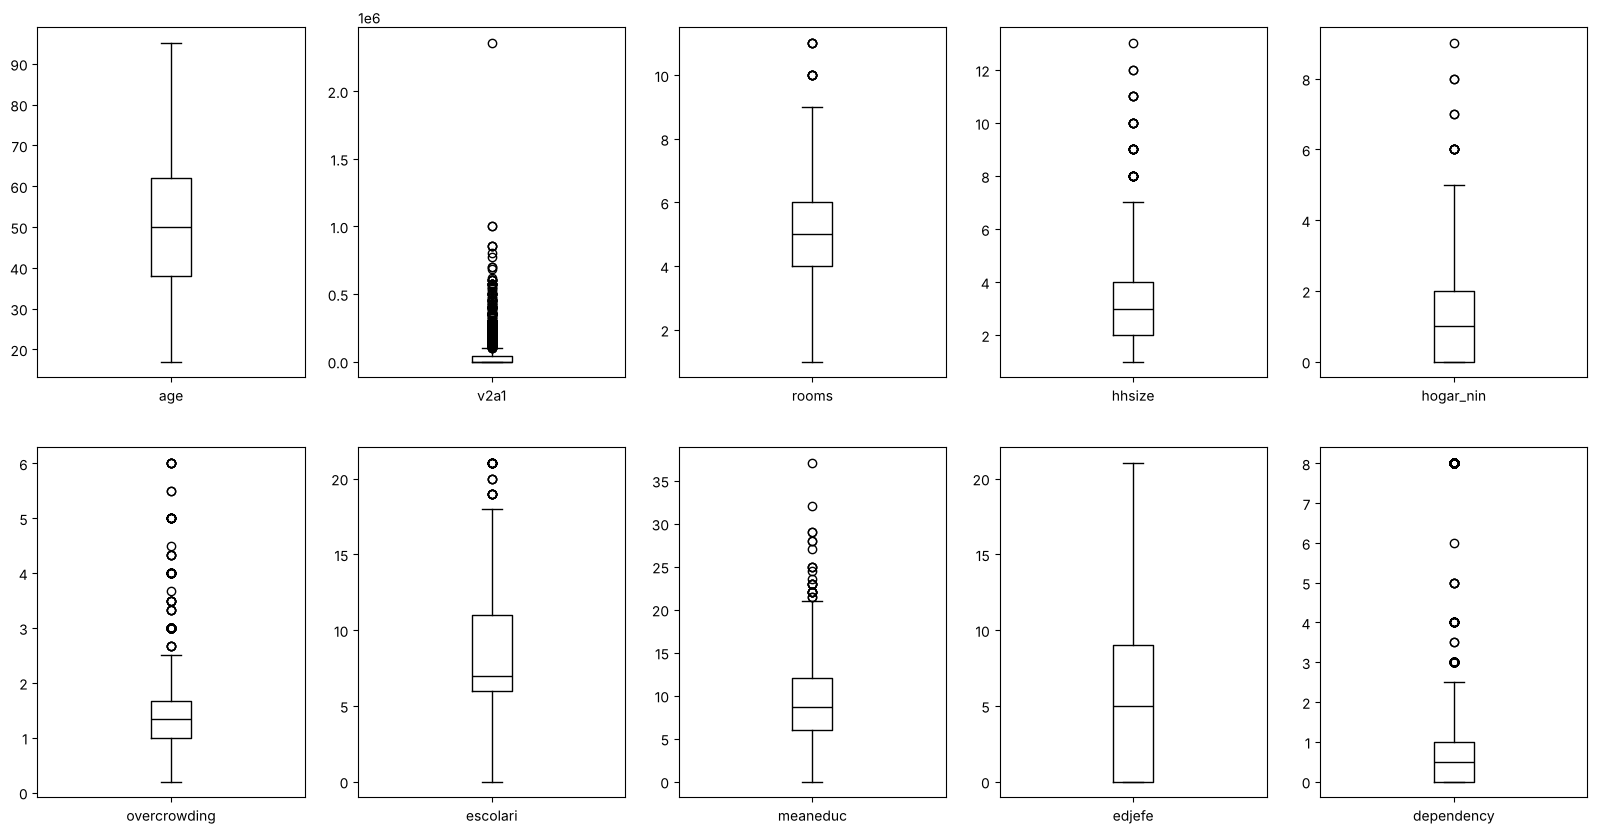

In [ ]:
'''Menampilkan boxplot seluruh data'''
# Data continuous (bukan nilai 0/1)
continous_features = ['age', 'v2a1', 'rooms', 'hhsize', 'hogar_nin',
                      'overcrowding', 'escolari', 'meaneduc', 'edjefe', 'dependency']

# Menampilkan boxplot untuk melihat outliers data numerik
data[continous_features].plot(kind = 'box', subplots = True, layout = (2,5), sharex = False, sharey = False, figsize = (20, 10), color = 'k')
plt.show()

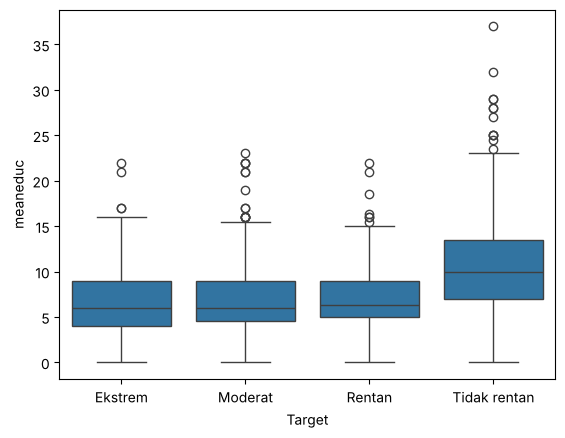

In [26]:
'''Menampilkan boxplot meaneduc per target'''
# Menampilkan data berdasarkan target untuk feature meaneduc
sns.boxplot(x='Target', y='meaneduc', data=data, order=target_order)
plt.show()

Data yang outliers terletak pada data non-categorical atau data continuous yaitu: 'age', 'v2a1', 'rooms', 'hhsize', 'hogar_nin', 'overcrowding', 'escolari', 'meaneduc', 'edjefe', dan 'dependency'.

In [ ]:
'''Menentukan data continous'''
#Mencari tahu data yang outliers dengan mendefinisikan fungsi
continous_features = ['age', 'v2a1', 'rooms', 'hhsize', 'hogar_nin',
                      'overcrowding', 'escolari', 'meaneduc', 'edjefe', 'dependency']
def outliers(data_out, drop = False):
    for each_feature in data_out.columns:
        feature_data = data_out[each_feature]
        Q1 = np.percentile(feature_data, 25.)
        Q3 = np.percentile(feature_data, 75.)
        IQR = Q3-Q1
        outlier_step = IQR * 1.5
        outliers = feature_data[~((feature_data >= Q1 - outlier_step) & (feature_data <= Q3 + outlier_step))].index.tolist()
        if not drop:
            print('untuk fitur {} ini, total outliers-nya {}'.format(each_feature, len(outliers)))
        if drop:
            data.drop(outliers, inplace = True, errors = 'ignore')
            print('Outliers dari {} fitur telah dihapus'.format(each_feature))

'''Menampilkan data yang outlier'''
outliers(data[continous_features])

For the feature age, Num of Outliers is 0
For the feature v2a1, Num of Outliers is 486
For the feature rooms, Num of Outliers is 10
For the feature hhsize, Num of Outliers is 35
For the feature hogar_nin, Num of Outliers is 12
For the feature overcrowding, Num of Outliers is 164
For the feature escolari, Num of Outliers is 25
For the feature meaneduc, Num of Outliers is 25
For the feature edjefe, Num of Outliers is 0
For the feature dependency, Num of Outliers is 331


Tidak semua outlier perlu dihapus. Outlier pada `v2a1` (sewa mahal), `overcrowding` (hunian sangat padat), `dependency`, dan `hogar_nin` adalah **kondisi nyata** yang justru menjadi ciri rumah tangga miskin, sehingga dipertahankan agar informasi penting tidak hilang. Outlier yang dihapus hanya pada feature yang nilainya tidak wajar atau sangat jarang: `rooms`, `hhsize`, `escolari`, dan `meaneduc` (misalnya rata-rata sekolah 37 tahun).

In [28]:
'''Menghapus data yang outlier'''
# Menghapus outlier dengan fungsi sebelumnya
print("Jumlah baris sebelum hapus outlier:", data.shape[0])
outliers(data[['rooms', 'hhsize', 'escolari', 'meaneduc']], drop = True)
print("Jumlah baris setelah hapus outlier:", data.shape[0])

Jumlah baris sebelum hapus outlier: 2973
Outliers from rooms feature removed
Outliers from hhsize feature removed
Outliers from escolari feature removed
Outliers from meaneduc feature removed
Jumlah baris setelah hapus outlier: 2882


Melihat informasi dari kategori dari data kategorikal.

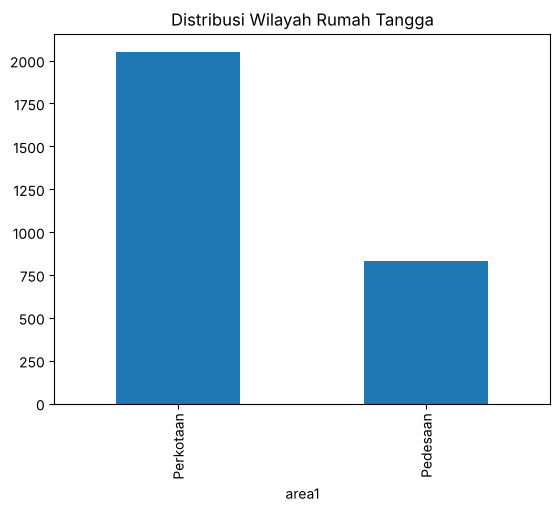

In [29]:
'''Buatlah histogram wilayah'''
# Jumlah kategori area pada dataset
data['area1'].value_counts().plot(kind='bar')
plt.title('Distribusi Wilayah Rumah Tangga')
plt.show()

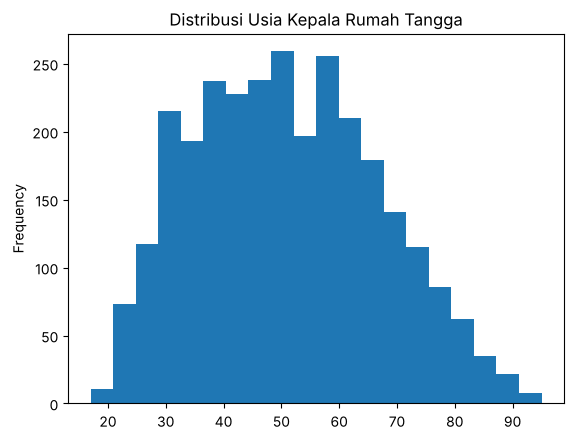

In [30]:
'''Buatlah histogram age'''
# Sebaran usia kepala rumah tangga
data['age'].plot(kind='hist', bins=20)
plt.title('Distribusi Usia Kepala Rumah Tangga')
plt.show()

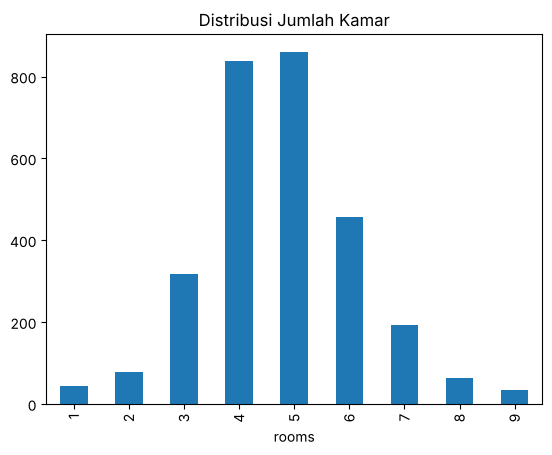

In [31]:
'''Buatlah histogram rooms'''
# Jumlah kategori rooms pada dataset
data['rooms'].value_counts().sort_index().plot(kind='bar')
plt.title('Distribusi Jumlah Kamar')
plt.show()

Selanjutnya, melakukan pengecekan data, apakah target imbalance?

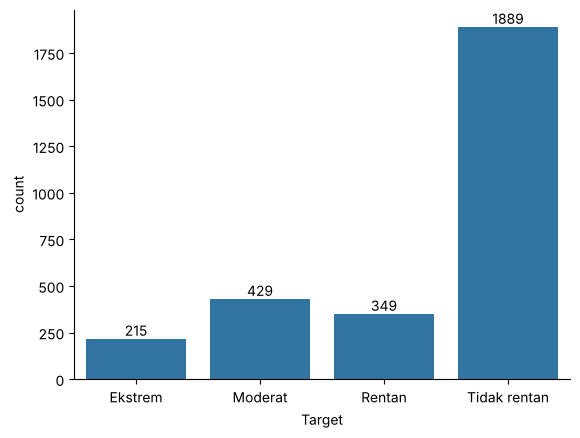

Target
Ekstrem          7.5
Moderat         14.9
Rentan          12.1
Tidak rentan    65.5
Name: proportion, dtype: float64


In [32]:
'''Memeriksa data yang imbalance'''
# Memeriksa data imbalance
ax = sns.countplot(x='Target', data=data, order=target_order)
for label in ax.containers:
    ax.bar_label(label)
sns.despine()
plt.show()

print((data['Target'].value_counts(normalize=True)[target_order] * 100).round(1))

Dapat dilihat pada output diatas data **tidak seimbang (imbalanced)**. Rumah tangga **tidak rentan** mendominasi dengan 65,5%, sedangkan **moderat** 14,9%, **rentan** 12,1%, dan **ekstrem** hanya 7,5%. Ketidakseimbangan ini penting diperhatikan di tahap pemodelan: model yang selalu menebak "tidak rentan" sudah akan mendapat akurasi sekitar 65%, tetapi gagal menemukan rumah tangga miskin. Karena itu pada Capstone II kita memakai `class_weight='balanced'` dan membaca *recall* serta *F1 macro* di samping akurasi.

**Periksa statistik deskriptif dari kumpulan data (rata-rata, distribusi, dll)**

In [33]:
# Melihat statistik deskriptif dari data
data[continous_features].describe()

,age,v2a1,rooms,hhsize,hogar_nin,overcrowding,escolari,meaneduc,edjefe,dependency
count,2882.00000,2.882000e+03,2882.000000,2882.000000,2882.000000,2882.000000,2882.000000,2882.000000,2882.000000,2882.000000
mean,50.93338,4.424160e+04,4.751908,3.139833,0.915337,1.359756,8.019778,8.954711,4.922276,1.330430
std,15.87662,1.089676e+05,1.402335,1.441518,1.073059,0.719026,4.380619,4.088556,5.192597,2.162165
min,17.00000,0.000000e+00,1.000000,1.000000,0.000000,0.200000,0.000000,0.000000,0.000000,0.000000
25%,38.00000,0.000000e+00,4.000000,2.000000,0.000000,1.000000,6.000000,6.000000,0.000000,0.000000
50%,50.00000,0.000000e+00,5.000000,3.000000,1.000000,1.291667,6.000000,8.500000,5.000000,0.500000
75%,62.00000,3.500000e+04,6.000000,4.000000,2.000000,1.666667,11.000000,11.500000,9.000000,1.000000
max,95.00000,2.353477e+06,9.000000,7.000000,6.000000,6.000000,18.000000,21.000000,18.000000,8.000000


Dari kumpulan data yang diberikan, dapat dilihat bahwa terdapat 2.882 rumah tangga setelah pembersihan. Berikut adalah statistik deskriptif dari beberapa variabel penting:

1. age: usia kepala rumah tangga, rata-rata 50,9 tahun dengan rentang 17 hingga 95 tahun.
2. v2a1: sewa bulanan, median 0 karena sebagian besar rumah tangga tidak menyewa. Rata-rata 44.242 colón dan maksimum sangat jauh di atasnya (distribusi sangat miring ke kanan).
3. rooms: jumlah kamar rata-rata 4,75 (1 hingga 9).
4. hhsize: ukuran rumah tangga rata-rata 3,14 orang (1 hingga 7).
5. overcrowding: rata-rata 1,36 orang per kamar dengan maksimum 6.
6. escolari dan meaneduc: lama sekolah kepala rumah tangga rata-rata 8,0 tahun dan rata-rata dewasa 8,95 tahun.
7. dependency: median 0,5 tetapi maksimum 8, artinya sebagian rumah tangga memiliki beban tanggungan yang sangat besar.

Selanjutnya, melihat distribusi data countinous (non-categorical).

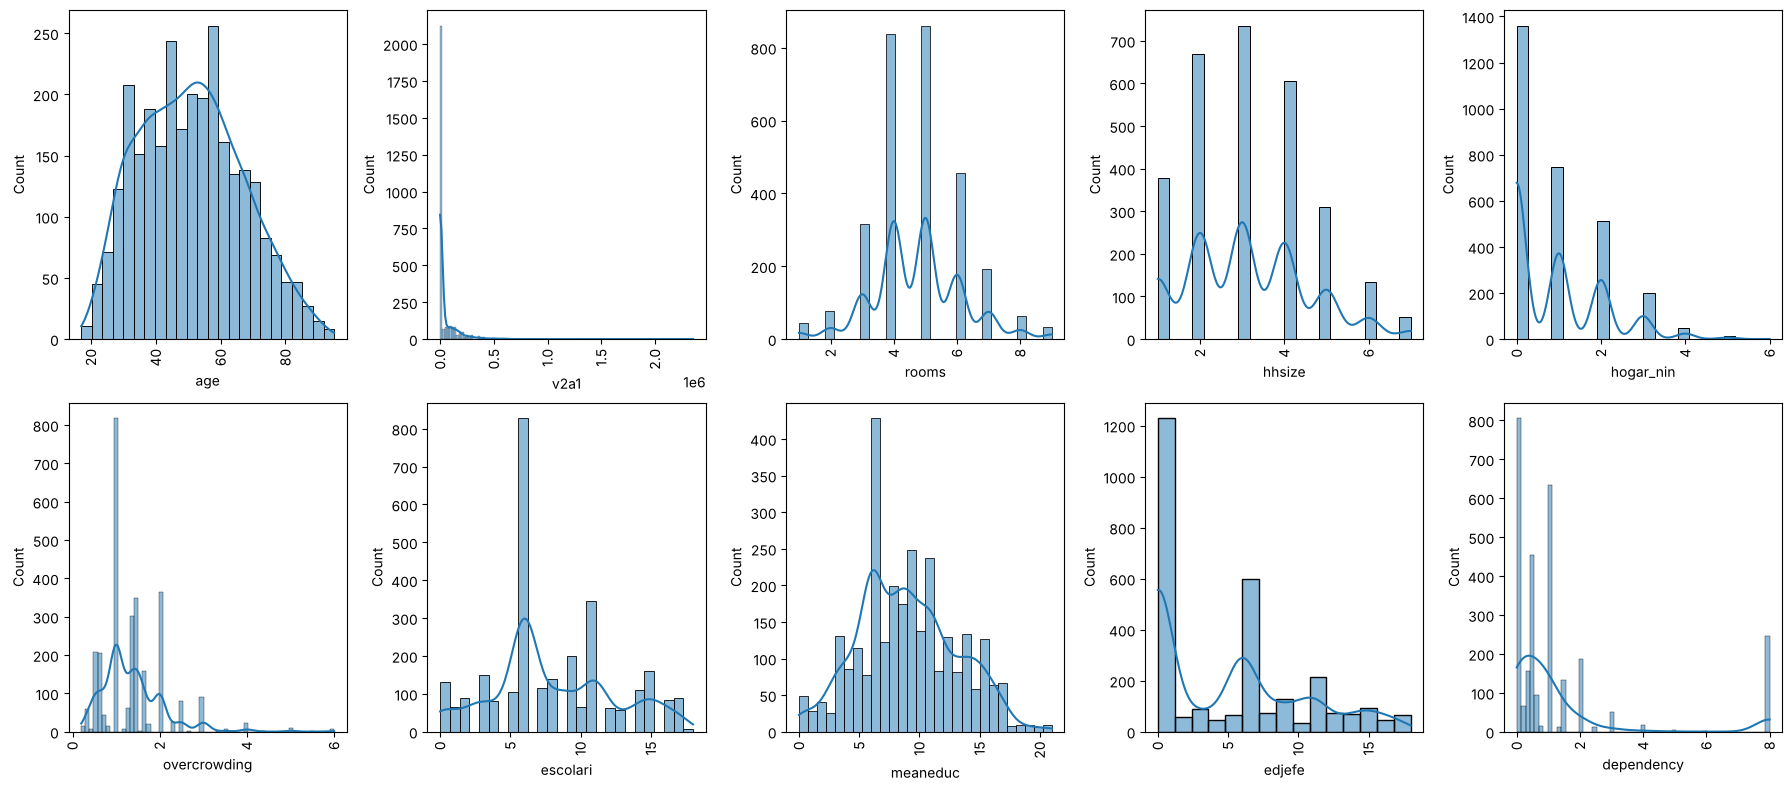

In [34]:
# Memvisualisasikan distribusi variabel numerical
plt.figure(figsize=(18,8))
for index,column in enumerate(continous_features):
    plt.subplot(2,5,index+1)
    sns.histplot(data=data,x=column,kde=True)
    plt.xticks(rotation = 90)
plt.tight_layout(pad = 1.0)
plt.show()

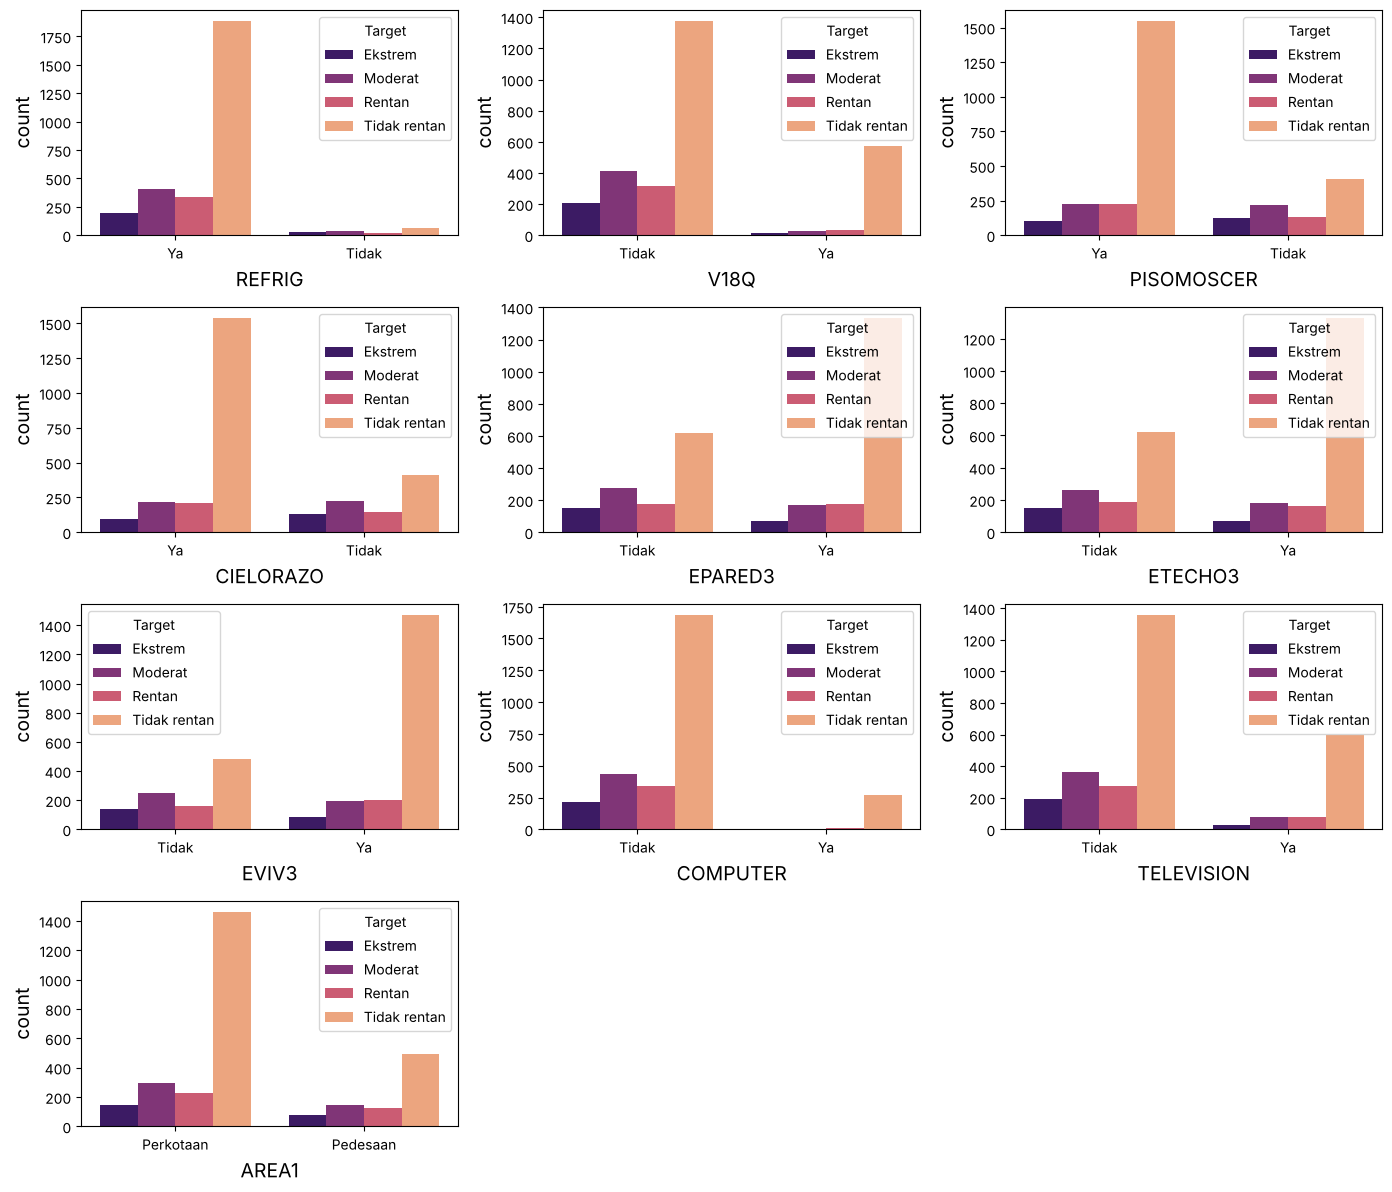

In [35]:
# Memvisualisasikan distribusi variabel kategorikal
plt.figure(figsize=(14,12))
cat_to_plot = [c for c in categorical_col if c != 'Target']
for index, column in enumerate(cat_to_plot):
    plt.subplot(4, 3, index+1)
    sns.countplot(data=categorical_col,x=column, hue='Target', hue_order=target_order, palette='magma')
    plt.xlabel(column.upper(),fontsize=14)
    plt.ylabel("count", fontsize=14)

plt.tight_layout(pad = 1.0)
plt.show()

Melihat korelasi antar feature.

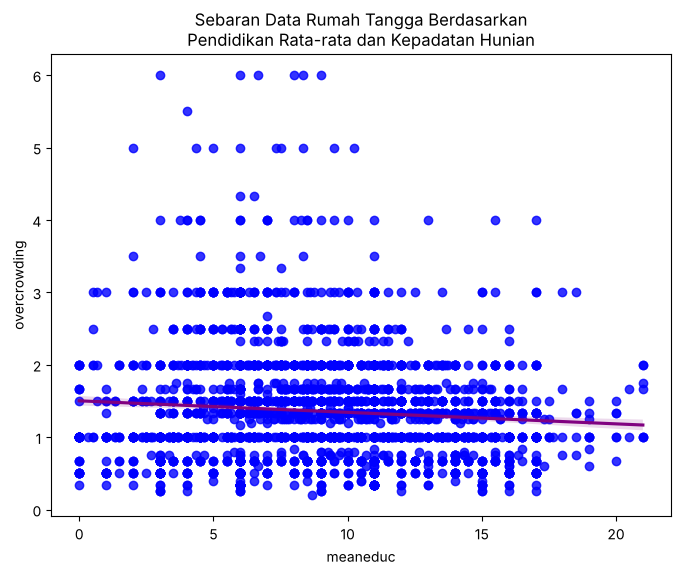

In [36]:
'''Menampilkan meaneduc dengan overcrowding'''
# melihat korelasi tingkat pendidikan dan kepadatan hunian
plt.figure(figsize = (8,6))
sns.regplot(x='meaneduc', y='overcrowding', data=data, scatter_kws = {'color':'blue'}, line_kws = {'color':'purple'})
plt.title('Sebaran Data Rumah Tangga Berdasarkan\nPendidikan Rata-rata dan Kepadatan Hunian')
plt.show()

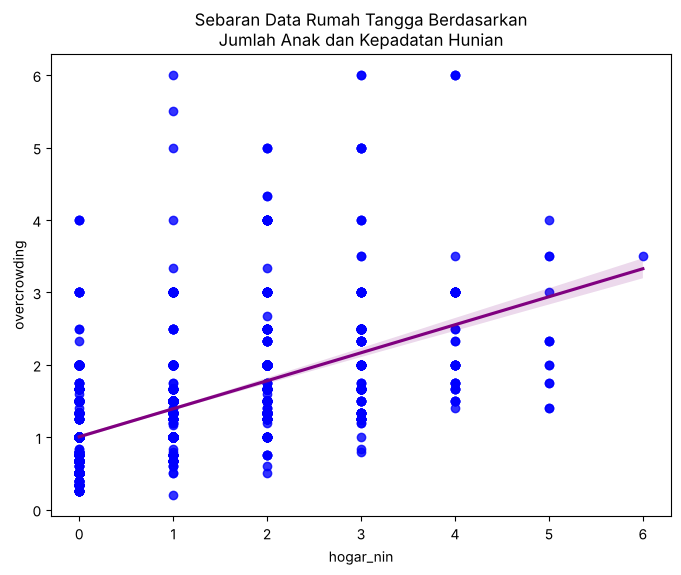

In [37]:
'''Menampilkan hogar_nin dengan overcrowding'''
# melihat korelasi jumlah anak dan kepadatan hunian
plt.figure(figsize = (8,6))
sns.regplot(x='hogar_nin', y='overcrowding', data=data, scatter_kws = {'color':'blue'}, line_kws = {'color':'purple'})
plt.title('Sebaran Data Rumah Tangga Berdasarkan\nJumlah Anak dan Kepadatan Hunian')
plt.show()

In [38]:
# Korelasi dua pasangan variabel di atas
print("Korelasi meaneduc vs overcrowding :", round(data['meaneduc'].corr(data['overcrowding']), 3))
print("Korelasi hogar_nin vs overcrowding:", round(data['hogar_nin'].corr(data['overcrowding']), 3))

Korelasi meaneduc vs overcrowding : -0.09
Korelasi hogar_nin vs overcrowding: 0.577


Kesimpulan dari grafik: jumlah anak (`hogar_nin`) berkorelasi positif cukup kuat dengan kepadatan hunian (r = 0,58), artinya semakin banyak anak, semakin padat rumah. Sebaliknya hubungan pendidikan rata-rata dewasa (`meaneduc`) dengan kepadatan hunian sangat lemah (r = -0,09), jadi kepadatan lebih banyak dipengaruhi komposisi keluarga daripada pendidikan.

In [39]:
# Simpan data yang sudah ada label
data.to_csv('data.csv')

# Melabeli kembali datanya
df = pd.read_csv('data.csv', index_col=0)
for col, mapping in label_maps.items():
    reverse_map = {label: value for value, label in mapping.items()}
    df[col] = df[col].map(reverse_map).astype(int)

df.shape

(2882, 141)

In [40]:
'''Menampilkan tabel korelasi'''
cor_matrix = df.corr()
cor_matrix

,v2a1,hacdor,rooms,hacapo,v14a,refrig,v18q,v18q1,r4h1,r4h2,...,SQBescolari,SQBage,SQBhogar_total,SQBedjefe,SQBhogar_nin,SQBovercrowding,SQBdependency,SQBmeaned,agesq,Target
v2a1,1.000000,-0.023589,0.078402,-0.018112,0.023794,0.040589,0.171700,0.190424,0.020987,-0.025269,...,0.306778,-0.202680,-0.006483,0.204399,0.007194,-0.026977,-0.103802,0.285329,-0.202680,0.161346
hacdor,-0.023589,1.000000,-0.192560,0.601932,-0.163283,-0.033093,-0.056551,-0.051573,0.139661,0.012756,...,-0.064926,-0.093923,0.152008,-0.048615,0.206433,0.729971,-0.022666,-0.059639,-0.093923,-0.115377
rooms,0.078402,-0.192560,1.000000,-0.190752,0.141494,0.160194,0.253439,0.260070,-0.059832,0.222964,...,0.249066,0.177535,0.216021,0.181029,0.007551,-0.326615,-0.009897,0.277914,0.177535,0.192617
hacapo,-0.018112,0.601932,-0.190752,1.000000,-0.192389,-0.015620,-0.047927,-0.041265,0.109392,0.010372,...,-0.055681,-0.069415,0.090954,-0.033859,0.105848,0.548182,-0.025835,-0.060515,-0.069415,-0.071837
v14a,0.023794,-0.163283,0.141494,-0.192389,1.000000,0.196549,0.029253,0.027645,-0.041320,0.019182,...,0.035764,0.028369,0.013201,0.023478,-0.017032,-0.128734,0.007233,0.039040,0.028369,0.069182
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SQBovercrowding,-0.026977,0.729971,-0.326615,0.548182,-0.128734,-0.035628,-0.081452,-0.072385,0.334061,0.131178,...,-0.145926,-0.227994,0.424563,-0.074394,0.436294,1.000000,-0.123853,-0.113301,-0.227994,-0.207648
SQBdependency,-0.103802,-0.022666,-0.009897,-0.025835,0.007233,-0.015131,-0.087059,-0.080623,-0.111257,-0.210124,...,-0.071834,0.492528,-0.244824,-0.038907,-0.092650,-0.123853,1.000000,-0.120889,0.492528,-0.051614
SQBmeaned,0.285329,-0.059639,0.277914,-0.060515,0.039040,0.115882,0.338711,0.326515,-0.026655,-0.014321,...,0.785814,-0.179453,0.010972,0.523414,0.033774,-0.113301,-0.120889,1.000000,-0.179453,0.308846
agesq,-0.202680,-0.093923,0.177535,-0.069415,0.028369,0.025898,-0.089951,-0.085372,-0.292623,0.005172,...,-0.185841,1.000000,-0.183867,-0.104886,-0.314924,-0.227994,0.492528,-0.179453,1.000000,0.012447


In [41]:
#Mengurutkan korelasi Target (kolom SQB adalah kuadrat kolom lain sehingga tidak ikut dipilih)
cor_target = cor_matrix['Target'].drop('Target').dropna()
cor_target = cor_target[~cor_target.index.str.startswith('SQB')]
cor_sorted = cor_target.sort_values()

print("10 korelasi negatif terkuat:\n", cor_sorted.head(10), "\n")
print("10 korelasi positif terkuat:\n", cor_sorted.tail(10))

10 korelasi negatif terkuat:
 hogar_nin      -0.261308
r4t1           -0.251491
overcrowding   -0.221731
eviv1          -0.210851
etecho1        -0.209402
epared1        -0.207061
pisocemento    -0.200903
r4m1           -0.198388
instlevel2     -0.181779
r4h1           -0.174999
Name: Target, dtype: float64 

10 korelasi positif terkuat:
 edjefe         0.234333
instlevel8     0.235689
paredblolad    0.249005
etecho3        0.256574
pisomoscer     0.266093
epared3        0.276271
eviv3          0.287806
cielorazo      0.289060
escolari       0.328280
meaneduc       0.342935
Name: Target, dtype: float64


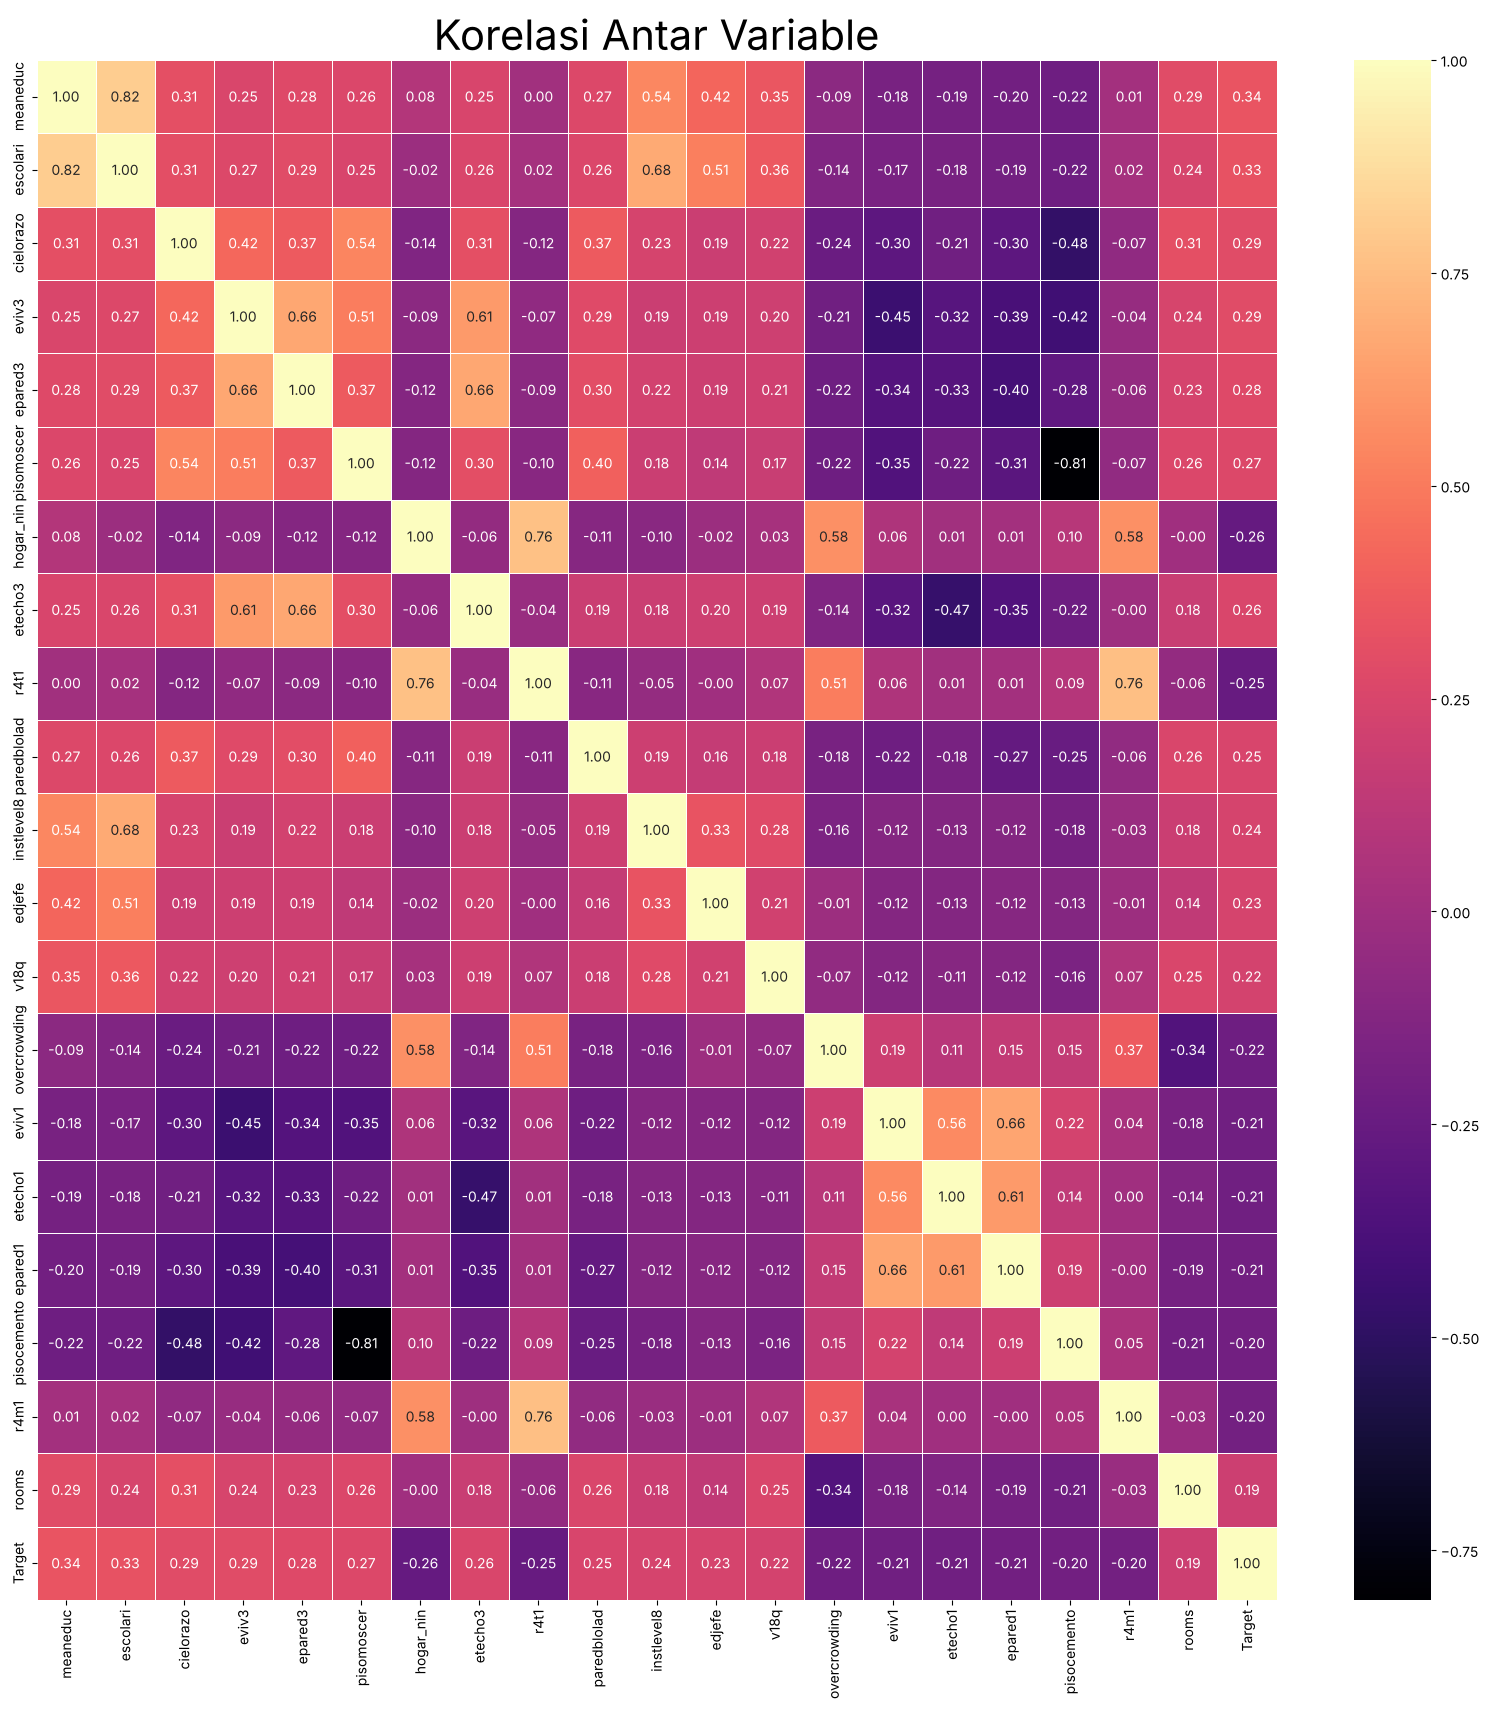

In [42]:
'''Menampilkan grafik korelasi'''
# melihat korelasi antar variable untuk mencari feature yang penting (20 feature dengan korelasi terkuat)
top20 = cor_target.abs().sort_values(ascending=False).head(20).index.tolist()
plt.figure(figsize=(20,20))
cor = df[top20 + ['Target']].corr()
sns.heatmap(cor,annot=True, linewidth=.5, cmap="magma", fmt='.2f')
plt.title('Korelasi Antar Variable', fontsize = 30)
plt.show()

Perlu diingat arah `Target`: nilai yang lebih besar berarti **semakin tidak miskin** (1 = ekstrem, 4 = tidak rentan). Korelasi positif dengan variabel tertentu berarti semakin tinggi variabel tersebut maka rumah tangga cenderung semakin sejahtera, sedangkan korelasi negatif berarti semakin tinggi variabel tersebut rumah tangga cenderung semakin miskin.

Korelasi terkuat (kolom `SQB` diabaikan karena hanya kuadrat dari kolom lain):

1. meaneduc 0,343 (korelasi positif)
2. escolari 0,328 (korelasi positif)
3. cielorazo 0,289 (korelasi positif)
4. eviv3 0,288 (korelasi positif)
5. epared3 0,276 (korelasi positif)
6. pisomoscer 0,266 (korelasi positif)
7. etecho3 0,257 (korelasi positif)
8. edjefe 0,234 (korelasi positif)
9. hogar_nin -0,261 (korelasi negatif)
10. overcrowding -0,222 (korelasi negatif)

Jadi, faktor yang paling berpengaruh terhadap tingkat kemiskinan rumah tangga ialah:

1. Pendidikan (`meaneduc`, `escolari`, `edjefe`): semakin tinggi pendidikan, semakin kecil kemungkinan rumah tangga miskin.
2. Kondisi fisik rumah (`cielorazo`, `eviv3`, `epared3`, `pisomoscer`, `etecho3`): rumah dengan langit-langit, lantai, dinding, dan atap yang baik berasosiasi dengan rumah tangga yang lebih sejahtera.
3. Komposisi keluarga (`hogar_nin`, `overcrowding`): banyak anak dan hunian yang padat berasosiasi dengan kemiskinan yang lebih parah.

Kesimpulan.

1. Seluruh korelasi tergolong lemah hingga sedang (maksimum sekitar 0,34), sehingga tidak ada satu variabel yang cukup untuk memprediksi `Target`. Perlu kombinasi beberapa feature.
2. `meaneduc` dan `escolari` berkorelasi positif paling kuat dengan `Target`.
3. Feature kondisi rumah (`cielorazo`, `eviv3`, `epared3`, `pisomoscer`, `etecho3`) saling berkaitan karena sama-sama mencerminkan kualitas bangunan.

Feature yang dipilih yaitu: 'escolari', 'meaneduc', 'cielorazo', 'eviv3', 'epared3', 'pisomoscer', 'etecho3', 'hogar_nin', 'overcrowding', 'v18q', 'rooms', dan 'edjefe' untuk dianalisa lebih lanjut. Kolom `v18q` (memiliki tablet) dan `rooms` (jumlah kamar) ikut dipilih karena mewakili aset dan ukuran rumah yang tidak tercakup variabel lain.

In [43]:
'''Memasukkan variabel terpilih diatas'''
variabel = ['escolari', 'meaneduc', 'cielorazo', 'eviv3', 'epared3', 'pisomoscer',
            'etecho3', 'hogar_nin', 'overcrowding', 'v18q', 'rooms', 'edjefe']
analyze = df[variabel]

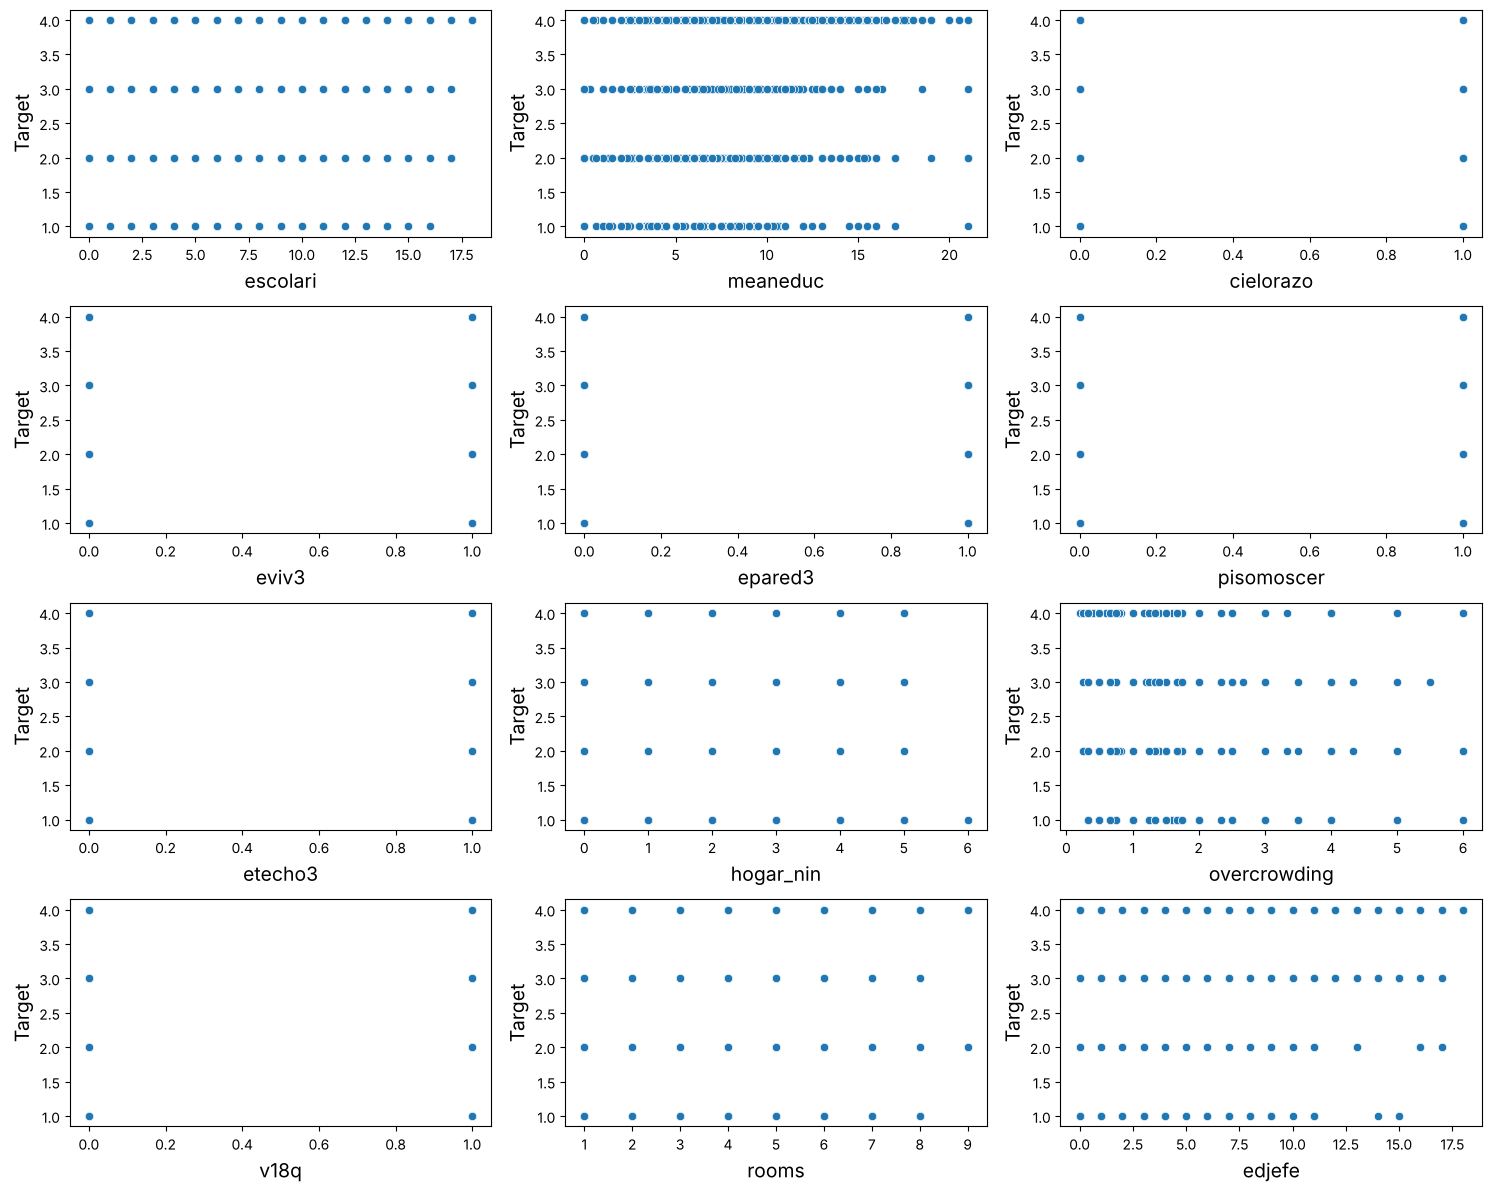

In [44]:
# Informasi variabel ke target
fig = plt.figure(figsize=(15,12))
for index in range(len(analyze.columns)):
    plt.subplot(4,3,index + 1)
    sns.scatterplot(x = analyze.iloc[:,index],y=df.Target,data = analyze)
    plt.xlabel(analyze.columns[index], fontsize=14)
    plt.ylabel("Target", fontsize=14)

fig.tight_layout(pad = 1.0)

**Scaling data**

Scaling adalah suatu cara untuk membuat numerical data pada dataset memiliki rentang nilai (scale) yang sama. Tidak ada lagi satu variabel data yang mendominasi variabel data lainnya.

In [45]:
# Mendefinisikan standard scaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[variabel])

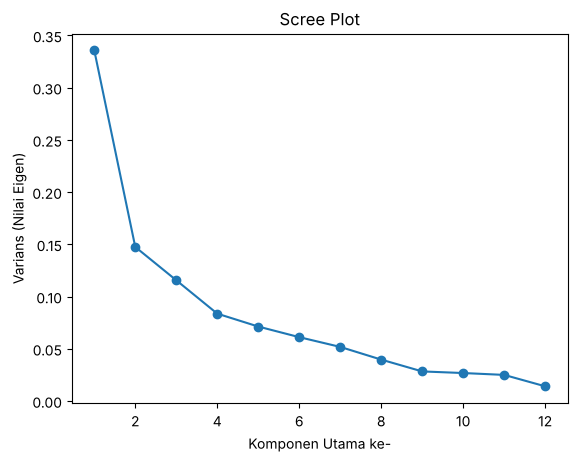

Varians kumulatif: [0.336 0.483 0.599 0.682 0.754 0.815 0.866 0.906 0.934 0.961 0.986 1.   ]


In [46]:
# Perform PCA for dimensionality reduction
feature_number = len(X_scaled[0])
pca = PCA(n_components=feature_number)

# Fit PCA with dataset
pca.fit(X_scaled)

# Get variance information
variance_ratio = pca.explained_variance_ratio_

# Calculate cummulative
cumulative_variance = np.cumsum(variance_ratio)

# Create Scree Plot
plt.plot(range(1, len(variance_ratio) + 1), variance_ratio, marker='o')
plt.xlabel('Komponen Utama ke-')
plt.ylabel('Varians (Nilai Eigen)')
plt.title('Scree Plot')
plt.show()

print("Varians kumulatif:", np.round(cumulative_variance, 3))

In [47]:
# Jumlah komponen minimal agar varians yang dijelaskan >= 90%
n_comp = int(np.argmax(cumulative_variance >= 0.90) + 1)
print("Jumlah komponen untuk 90% varians:", n_comp)

pca = PCA(n_components=n_comp)
poverty_data_reduced = pca.fit_transform(X_scaled)
poverty_data_reduced.shape

Jumlah komponen untuk 90% varians: 8


(2882, 8)

In [48]:
feature_names = list(analyze.columns)
component_names = [f"PC{i+1}" for i in range(pca.n_components_)]

for component, component_name in zip(pca.components_, component_names):
    feature_indices = component.argsort()[::-1]
    retained_features = [feature_names[idx] for idx in feature_indices[:5]]
    print(f"{component_name}: {retained_features}")

PC1: ['eviv3', 'epared3', 'escolari', 'etecho3', 'cielorazo']
PC2: ['hogar_nin', 'overcrowding', 'meaneduc', 'escolari', 'edjefe']
PC3: ['overcrowding', 'hogar_nin', 'etecho3', 'eviv3', 'epared3']
PC4: ['rooms', 'hogar_nin', 'pisomoscer', 'cielorazo', 'v18q']
PC5: ['pisomoscer', 'cielorazo', 'overcrowding', 'edjefe', 'escolari']
PC6: ['v18q', 'pisomoscer', 'cielorazo', 'overcrowding', 'eviv3']
PC7: ['edjefe', 'rooms', 'v18q', 'overcrowding', 'cielorazo']
PC8: ['cielorazo', 'etecho3', 'overcrowding', 'epared3', 'meaneduc']


Dari hasil PCA, 8 komponen utama sudah menjelaskan sekitar 90,6% varians dari 12 feature terpilih. Komponen pertama (PC1, sekitar 34% varians) didominasi oleh kondisi fisik rumah (`eviv3`, `epared3`, `etecho3`, `cielorazo`) dan pendidikan, sedangkan PC2 didominasi komposisi keluarga (`hogar_nin`, `overcrowding`). Karena jumlah feature hanya 12 dan setiap komponen masih mudah ditafsirkan, pada Capstone II tetap memakai 12 feature terpilih (tanpa PCA) agar hasil model lebih mudah dijelaskan.